MATRICE MAL CONDITIONNE



In [2]:

import numpy as np

# 1. Matrice mal conditionnée et second membre
A = np.array([
    [1.0, 1.0],
    [1.0, 1.000001]
])

b = np.array([2.0, 2.000001])

# 2. Nombre de conditionnement
print("Conditionnement initial :", np.linalg.cond(A))

# 3. Décomposition SVD
U, s, Vt = np.linalg.svd(A, full_matrices=False)

print("U =\n", U)
print("Valeurs singulières =", s)
print("Vt =\n", Vt)

# 4. Choisir le seuil et conserver les grandes valeurs
tol = 1e-5 * s[0]
keep = s > tol

print("Seuil =", tol)
print("Valeurs conservées =", s[keep])

# 5. Calcul de la solution tronquée
c = U.T @ b
x_trunc = Vt.T[:, keep] @ (c[keep] / s[keep])

print("Solution tronquée =", x_trunc)

# 6. Comparaison avec la solution exacte numérique
x_direct = np.linalg.solve(A, b)
print("Solution directe =", x_direct)

# 7. Résidu de la solution tronquée
residual = np.linalg.norm(A @ x_trunc - b)
print("Résidu =", residual)


Conditionnement initial : 4000002.0003309543
U =
 [[-0.7071066  -0.70710696]
 [-0.70710696  0.7071066 ]]
Valeurs singulières = [2.00000050e+00 4.99999875e-07]
Vt =
 [[-0.7071066  -0.70710696]
 [-0.70710696  0.7071066 ]]
Seuil = 2.0000005000001256e-05
Valeurs conservées = [2.0000005]
Solution tronquée = [0.99999975 1.00000025]
Solution directe = [1. 1.]
Résidu = 1.7680607542281838e-13


Regularisation

In [3]:

import numpy as np

# 1. Definir le systeme
A = np.array([
    [1.0, 0.0],
    [0.0, 0.001]
])

b = np.array([1.0, 0.001])

# 2. Solution sans regularisation
x = np.linalg.solve(A, b)

# 3. Definir la regularisation
L = np.eye(A.shape[1])
lam = 0.01

# 4. Construire les equations normales regularisees
M = A.T @ A + lam * (L.T @ L)
rhs = A.T @ b

# 5. Calculer la solution regularisee
x_reg = np.linalg.solve(M, rhs)

# 6. Comparer les resultats
print("Conditionnement de A :", np.linalg.cond(A))
print("Solution initiale :", x)
print("Solution regularisee :", x_reg)
print("Erreur initiale :", np.linalg.norm(A @ x - b))
print("Erreur regularisee :", np.linalg.norm(A @ x_reg - b))
print("Conditionnement de M :", np.linalg.cond(M))


Conditionnement de A : 1000.0
Solution initiale : [1. 1.]
Solution regularisee : [9.9009901e-01 9.9990001e-05]
Erreur initiale : 0.0
Erreur regularisee : 0.00995135191673414
Conditionnement de M : 100.98990100989901


PCA

In [13]:

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Creer les donnees
df = pd.DataFrame({
    "Etude": [1, 2, 3, 4, 5, 6],
    "Pratique": [2, 4, 6, 8, 10, 12],
    "Score": [10, 20, 30, 40, 50, 60]
})

print("Dataset initial :")
print(df)

# 2. Standardiser les variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 3. Reduire de 3 dimensions a 2
pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)

# 4. Afficher les resultats
df_reduit = pd.DataFrame(
    Z, columns=["PC1", "PC2"]
)

print("\nDataset apres PCA :")
print(df_reduit.round(4))

# 5. Information conservee
print("\nVariance expliquee :")
print(pca.explained_variance_ratio_)

print(
    "Variance totale conservee :",
    pca.explained_variance_ratq[
    4io_.sum()
)


Dataset initial :
   Etude  Pratique  Score
0      1         2     10
1      2         4     20
2      3         6     30
3      4         8     40
4      5        10     50
5      6        12     60

Dataset apres PCA :
      PC1
0 -2.5355
1 -1.5213
2 -0.5071
3  0.5071
4  1.5213
5  2.5355

Variance expliquee :
[1.]
Variance totale conservee : 1.0


In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


factory analysis

In [14]:

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis

# 1. Creer le dataset
df = pd.DataFrame({
    "Maths": [12, 14, 10, 16, 8, 18, 11, 15, 9, 17],
    "Physique": [11, 13, 9, 15, 10, 17, 12, 14, 8, 16],
    "Informatique": [13, 15, 11, 17, 9, 18, 10, 16, 10, 15]
})

print("Dataset initial :")
print(df)

# 2. Standardiser les variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 3. Construire le modele FA
fa = FactorAnalysis(n_components=1, random_state=42)

# 4. Estimer le facteur latent
factor_scores = fa.fit_transform(X_scaled)

# 5. Afficher les coefficients factoriels
loadings = pd.DataFrame(
    fa.components_.T,
    index=df.columns,
    columns=["Facteur_1"]
)

print("\nCoefficients factoriels :")
print(loadings.round(3))

# 6. Afficher le score latent de chaque etudiant
scores = pd.DataFrame({
    "Etudiant": list("ABCDEFGHIJ"),
    "Facteur_1": factor_scores[:, 0]
})

print("\nScores factoriels :")
print(scores.round(3))

# 7. Variance specifique estimee
print("\nVariances specifiques :")
print(pd.Series(
    fa.noise_variance_,
    index=df.columns
).round(3))


Dataset initial :
   Maths  Physique  Informatique
0     12        11            13
1     14        13            15
2     10         9            11
3     16        15            17
4      8        10             9
5     18        17            18
6     11        12            10
7     15        14            16
8      9         8            10
9     17        16            15

Coefficients factoriels :
              Facteur_1
Maths             0.998
Physique          0.956
Informatique      0.952

Scores factoriels :
  Etudiant  Facteur_1
0        A     -0.305
1        B      0.306
2        C     -0.916
3        D      0.917
4        E     -1.476
5        F      1.513
6        G     -0.606
7        H      0.611
8        I     -1.222
9        J      1.178

Variances specifiques :
Maths           0.005
Physique        0.087
Informatique    0.093
dtype: float64


Analyse des Correspondances

          Python  Java  C++
Bachelor      20    10   10
Master        25    15    5
PhD            5     5    5
[[20 10 10]
 [25 15  5]
 [ 5  5  5]]

 la matrice de frequence : 
          Python  Java   C++
Bachelor    0.20  0.10  0.10
Master      0.25  0.15  0.05
PhD         0.05  0.05  0.05
Masses des lignes :
Bachelor    0.40
Master      0.45
PhD         0.15
dtype: float64

Masses des colonnes :
Python    0.5
Java      0.3
C++       0.2
dtype: float64
          Python  Java  C++
Bachelor    20.0  12.0  8.0
Master      22.5  13.5  9.0
PhD          7.5   4.5  3.0

 the total inertia is : 
0.052779999999999994
les profil des lignes :
          Python    Java     C++
Bachelor  0.5000  0.2500  0.2500
Master    0.5556  0.3333  0.1111
PhD       0.3333  0.3333  0.3333
les profils colonnes : 
          Python    Java   C++
Bachelor     0.4  0.3333  0.50
Master       0.5  0.5000  0.25
PhD          0.1  0.1667  0.25
Distance au carré : 0.1257716049382716
Distance : 0.35464292596676955
Matrice

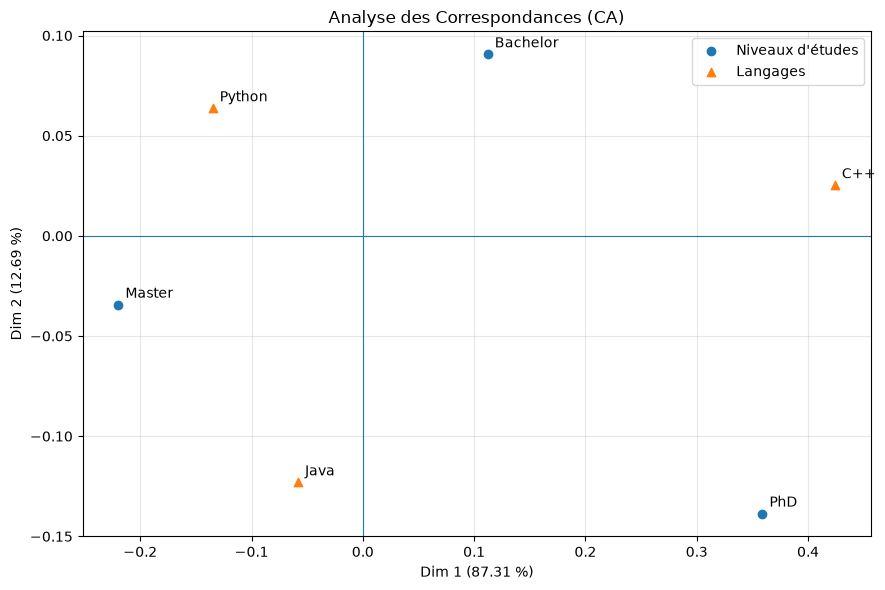

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N = pd.DataFrame(
    {
        "Python": [20, 25, 5],
        "Java":   [10, 15, 5],
        "C++":    [10, 5, 5]
    },
    index=["Bachelor", "Master", "PhD"]
)

print(N)
n= N.to_numpy().sum()

P = N/n

print(N.to_numpy())

print("\n la matrice de frequence : ")
print(P)

#Calculer les masses de lignes et de colonnes

r =P.sum(axis=1)
c = P.sum(axis=0)

print("Masses des lignes :")
print(r)

print("\nMasses des colonnes :")
print(c)

E = n*np.outer(r,c)
E = pd.DataFrame(E , index = N.index , columns = N.columns)
print(E)

#calculer le khi-deux
khi_deux = (((N-E)**2)/E)
total_inertia =khi_deux.to_numpy().sum()
print("\n the total inertia is : ")
print(total_inertia.round(3)/n)

#calculer les prophiles des lignes :
row_profiles = N.div(N.sum(axis=1),axis=0)
print("les profil des lignes :")
print(row_profiles.round(4))

#Calculer les profils de colonnes : 
column_profiles = N.div(N.sum(axis=0))
print("les profils colonnes : ")
print(column_profiles.round(4))

profile_bachelor = row_profiles.loc["Bachelor"].to_numpy()
profile_master = row_profiles.loc["Master"].to_numpy()

column_masses = c.to_numpy()

distance_squared = np.sum(
    (profile_bachelor - profile_master) ** 2 / column_masses
)

distance = np.sqrt(distance_squared)

print("Distance au carré :", distance_squared)
print("Distance :", distance)

P_array = P.to_numpy()
r_array = r.to_numpy()
c_array = c.to_numpy()

Dr_inv_sqrt = np.diag(1 / np.sqrt(r_array))
Dc_inv_sqrt = np.diag(1 / np.sqrt(c_array))

S = Dr_inv_sqrt @ (
    P_array - np.outer(r_array, c_array)
) @ Dc_inv_sqrt

print("Matrice standardisée S :")
print(np.round(S, 4))

U, singular_values, Vt = np.linalg.svd(
    S,
    full_matrices=False
)

print("Valeurs singulières :")
print(singular_values)

eigenvalues = singular_values ** 2

print("\nValeurs propres (inerties des axes) :")
print(eigenvalues)



total = eigenvalues.sum()

explained_inertia = eigenvalues / total * 100

for i, percentage in enumerate(explained_inertia, start=1):
    print(f"Axe {i} : {percentage:.2f}%")
# Coordonnées principales des lignes
F = Dr_inv_sqrt @ U @ np.diag(singular_values)

# Coordonnées principales des colonnes
G = Dc_inv_sqrt @ Vt.T @ np.diag(singular_values)

row_coordinates = pd.DataFrame(
    F[:, :2],
    index=N.index,
    columns=["Dim1", "Dim2"]
)

column_coordinates = pd.DataFrame(
    G[:, :2],
    index=N.columns,
    columns=["Dim1", "Dim2"]
)

print("Coordonnées des lignes :")
print(row_coordinates.round(4))

print("\nCoordonnées des colonnes :")
print(column_coordinates.round(4))

fig, ax = plt.subplots(figsize=(9, 6))

# Catégories des lignes
ax.scatter(
    F[:, 0], F[:, 1],
    label="Niveaux d'études",
    marker="o"
)

for i, label in enumerate(N.index):
    ax.annotate(label, (F[i, 0], F[i, 1]), xytext=(5, 5),
                textcoords="offset points")

# Catégories des colonnes
ax.scatter(
    G[:, 0], G[:, 1],
    label="Langages",
    marker="^"
)

for j, label in enumerate(N.columns):
    ax.annotate(label, (G[j, 0], G[j, 1]), xytext=(5, 5),
                textcoords="offset points")

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)

ax.set_xlabel(f"Dim 1 ({explained_inertia[0]:.2f} %)")
ax.set_ylabel(f"Dim 2 ({explained_inertia[1]:.2f} %)")
ax.set_title("Analyse des Correspondances (CA)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
    